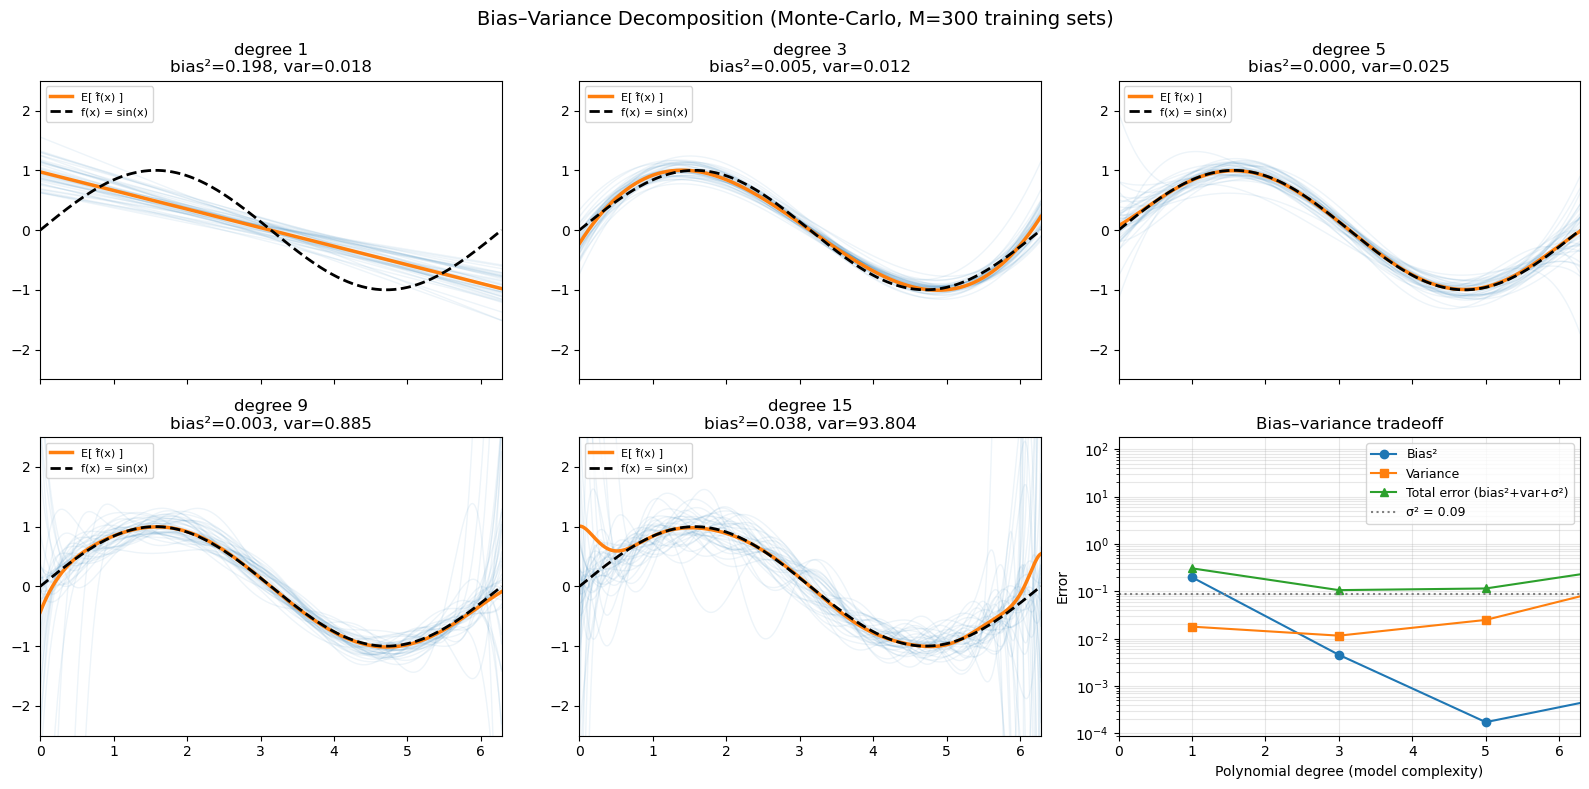

 degree     bias^2   variance      total
      1     0.1981     0.0180     0.3061
      3     0.0046     0.0116     0.1062
      5     0.0002     0.0249     0.1151
      9     0.0031     0.8854     0.9786
     15     0.0380    93.8036    93.9316


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(42)

# ----------------------------------------------------------------------
# 1. Ground truth and data-generating process
# ----------------------------------------------------------------------
X_MIN, X_MAX = 0.0, 2.0 * np.pi           # full period of sin(x)

def f_true(x):
    return np.sin(x)

def sample_dataset(n_samples, noise_std):
    x = rng.uniform(X_MIN, X_MAX, size=n_samples)
    y = f_true(x) + rng.normal(0, noise_std, size=n_samples)
    return x.reshape(-1, 1), y

NOISE_STD = 0.3
N_SAMPLES = 40

# Dense test grid covering the full period
x_test = np.linspace(X_MIN, X_MAX, 400).reshape(-1, 1)
y_true_test = f_true(x_test).ravel()

# ----------------------------------------------------------------------
# 2. Monte-Carlo experiment
# ----------------------------------------------------------------------
M = 300
degrees = [1, 3, 5, 9, 15]

results = {}
for deg in degrees:
    preds = np.zeros((M, x_test.shape[0]))
    for m in range(M):
        X_tr, y_tr = sample_dataset(N_SAMPLES, NOISE_STD)
        model = make_pipeline(PolynomialFeatures(degree=deg), LinearRegression())
        model.fit(X_tr, y_tr)
        preds[m] = model.predict(x_test)

    mean_pred = preds.mean(axis=0)
    bias_sq   = (mean_pred - y_true_test) ** 2
    variance  = preds.var(axis=0)

    results[deg] = dict(
        preds=preds,
        mean_pred=mean_pred,
        bias_sq_avg=bias_sq.mean(),
        var_avg=variance.mean(),
    )

# ----------------------------------------------------------------------
# 3. Visualization
# ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
axes = axes.ravel()

for ax, deg in zip(axes, degrees):
    r = results[deg]
    for m in range(min(40, M)):
        ax.plot(x_test.ravel(), r["preds"][m], color="C0", alpha=0.08, lw=1)
    ax.plot(x_test.ravel(), r["mean_pred"], color="C1", lw=2.5,
            label="E[ f̂(x) ]")
    ax.plot(x_test.ravel(), y_true_test, "k--", lw=2, label="f(x) = sin(x)")
    ax.set_title(f"degree {deg}\n"
                 f"bias²={r['bias_sq_avg']:.3f}, var={r['var_avg']:.3f}")
    ax.set_xlim(X_MIN, X_MAX)
    ax.set_ylim(-2.5, 2.5)
    ax.legend(fontsize=8, loc="upper left")

# last panel: bias², variance and total error vs. degree
ax = axes[-1]
deg_arr  = np.array(degrees)
bias_arr = np.array([results[d]["bias_sq_avg"] for d in degrees])
var_arr  = np.array([results[d]["var_avg"]     for d in degrees])
noise    = NOISE_STD ** 2
total    = bias_arr + var_arr + noise

ax.plot(deg_arr, bias_arr, "o-", label="Bias²")
ax.plot(deg_arr, var_arr,  "s-", label="Variance")
ax.plot(deg_arr, total,    "^-", label="Total error (bias²+var+σ²)")
ax.axhline(noise, color="gray", ls=":", label=f"σ² = {noise:.2f}")
ax.set_xlabel("Polynomial degree (model complexity)")
ax.set_ylabel("Error")
ax.set_yscale("log")
ax.set_title("Bias–variance tradeoff")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3)

fig.suptitle("Bias–Variance Decomposition (Monte-Carlo, M=%d training sets)" % M,
             fontsize=14)
fig.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 4. Numeric summary
# ----------------------------------------------------------------------
print(f"{'degree':>7} {'bias^2':>10} {'variance':>10} {'total':>10}")
for d in degrees:
    b = results[d]["bias_sq_avg"]
    v = results[d]["var_avg"]
    print(f"{d:>7} {b:>10.4f} {v:>10.4f} {b + v + NOISE_STD**2:>10.4f}")


    

/Users/salvadorruizcorrea/opt/anaconda3/lib/python3.8/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


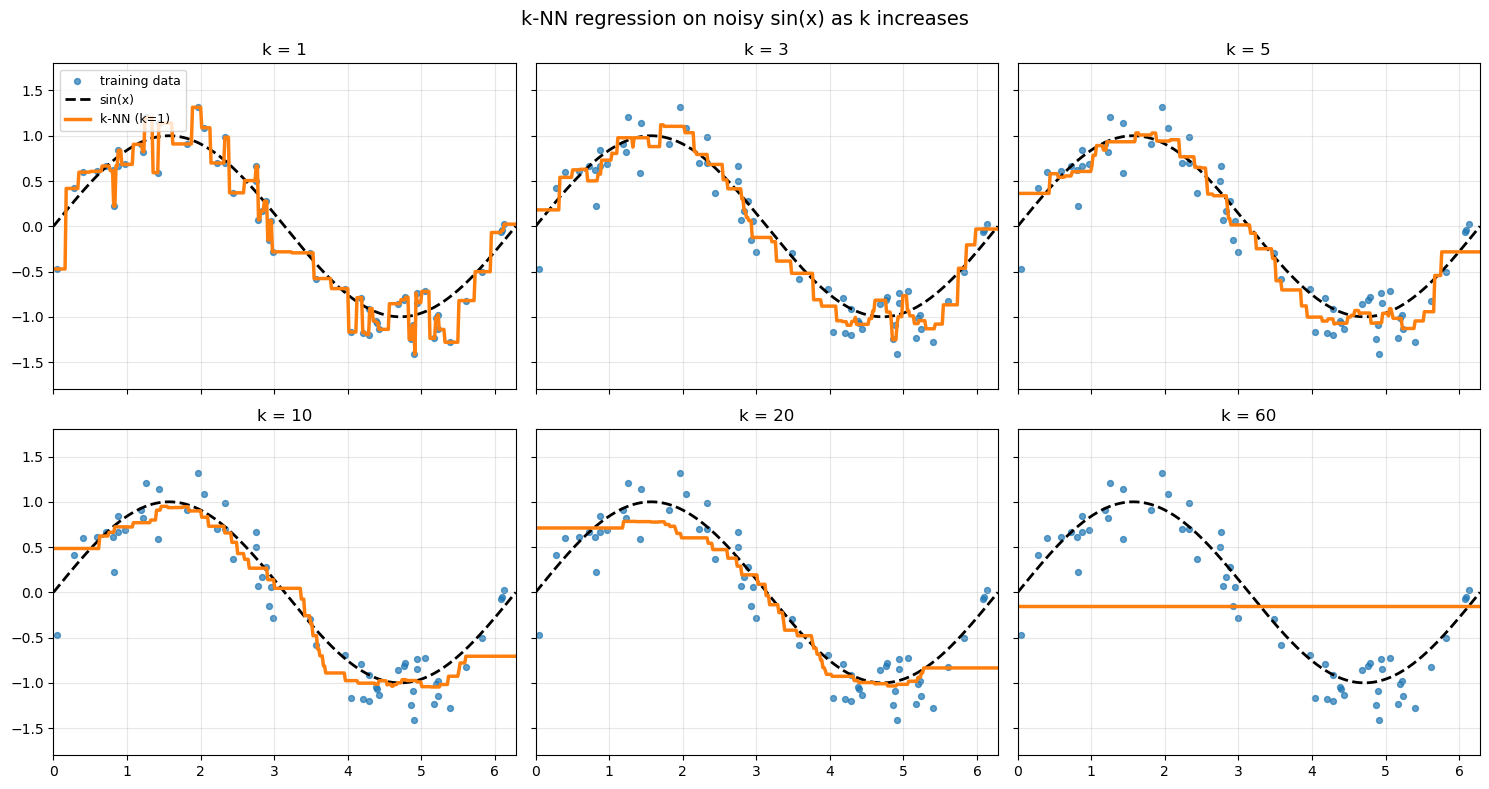

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor

rng = np.random.default_rng(42)

# Ground truth
X_MIN, X_MAX = 0.0, 2.0 * np.pi
f_true = np.sin

# One noisy training set
n = 60
X_train = rng.uniform(X_MIN, X_MAX, size=n).reshape(-1, 1)
y_train = f_true(X_train.ravel()) + rng.normal(0, 0.3, size=n)

# Dense test grid
x_test = np.linspace(X_MIN, X_MAX, 400).reshape(-1, 1)

# Sweep k
ks = [1, 3, 5, 10, 20, 60]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, k in zip(axes, ks):
    model = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    y_pred = model.predict(x_test)

    ax.scatter(X_train.ravel(), y_train, s=18, color="C0",
               alpha=0.7, label="training data")
    ax.plot(x_test.ravel(), f_true(x_test.ravel()), "k--", lw=2,
            label="sin(x)")
    ax.plot(x_test.ravel(), y_pred, color="C1", lw=2.5,
            label=f"k-NN (k={k})")
    ax.set_title(f"k = {k}")
    ax.set_xlim(X_MIN, X_MAX)
    ax.set_ylim(-1.8, 1.8)
    ax.grid(alpha=0.3)

axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle("k-NN regression on noisy sin(x) as k increases", fontsize=14)
fig.tight_layout()
plt.show()

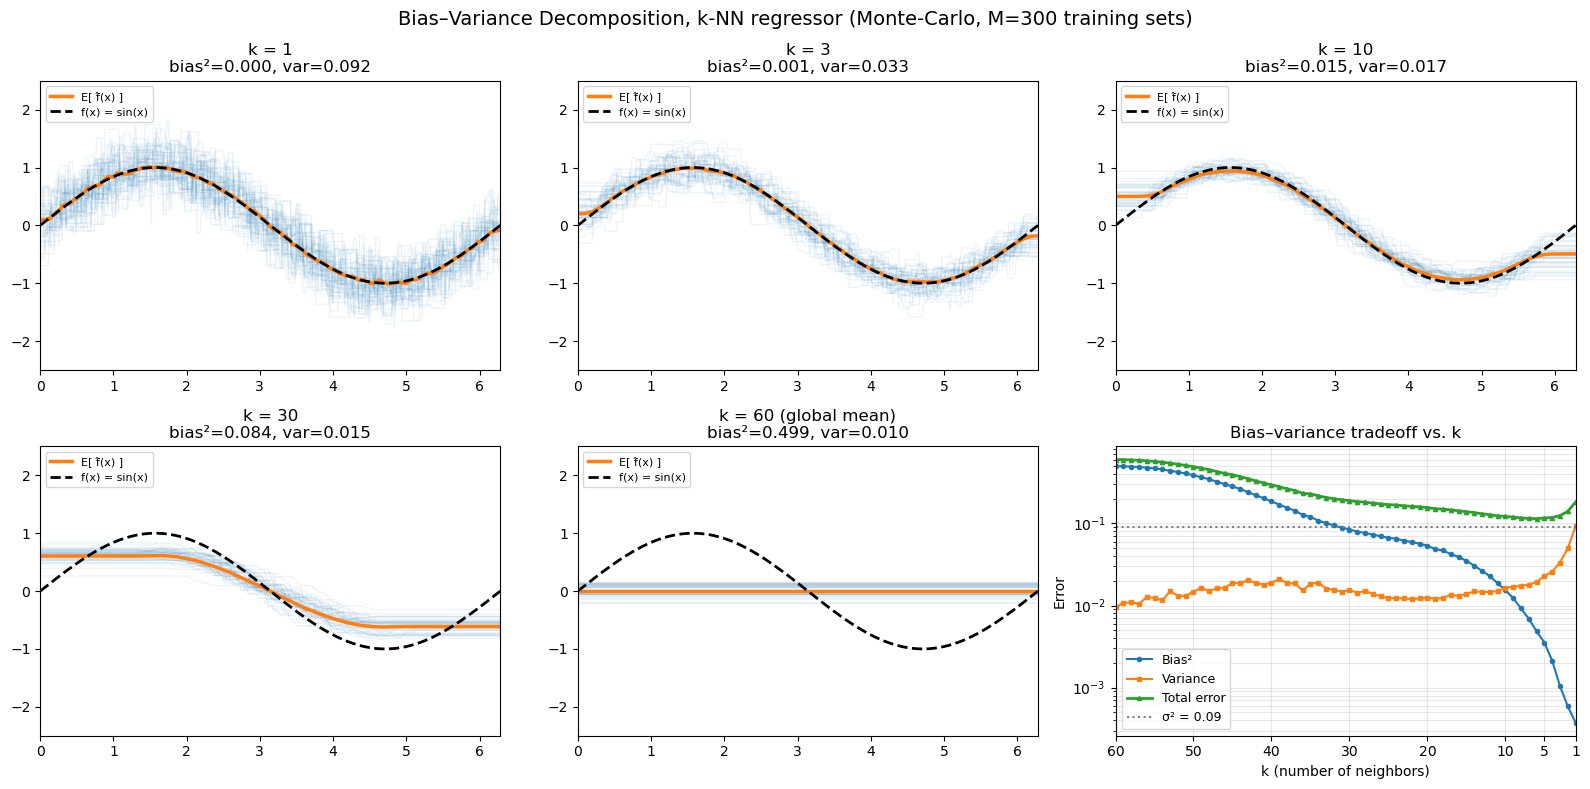

     k     bias^2   variance      total
     1     0.0004     0.0918     0.1822
     3     0.0010     0.0334     0.1244
    10     0.0153     0.0166     0.1219
    30     0.0841     0.0154     0.1895
    60     0.4988     0.0095     0.5983


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor

rng = np.random.default_rng(50)

# ----------------------------------------------------------------------
# 1. Ground truth and data-generating process
# ----------------------------------------------------------------------
X_MIN, X_MAX = 0.0, 2.0 * np.pi

def f_true(x):
    return np.sin(x)

def sample_dataset(n_samples, noise_std):
    x = rng.uniform(X_MIN, X_MAX, size=n_samples)
    y = f_true(x) + rng.normal(0, noise_std, size=n_samples)
    return x.reshape(-1, 1), y

NOISE_STD = 0.3
N_SAMPLES = 60

x_test = np.linspace(X_MIN, X_MAX, 400).reshape(-1, 1)
y_true_test = f_true(x_test).ravel()

# ----------------------------------------------------------------------
# 2. Monte-Carlo sweep over EVERY k in 1..N_SAMPLES
# ----------------------------------------------------------------------
M = 300
ks_all = np.arange(1, N_SAMPLES + 1)

# Panel snapshots — a few representative k values for the visual grid
k_snapshots = [1, 3, 10, 30, N_SAMPLES]

bias_curve   = np.zeros(len(ks_all))
var_curve    = np.zeros(len(ks_all))
total_curve  = np.zeros(len(ks_all))

snapshots = {}     # k -> dict(preds, mean_pred, bias_sq_avg, var_avg)

for j, k in enumerate(ks_all):
    preds = np.zeros((M, x_test.shape[0]))
    for m in range(M):
        X_tr, y_tr = sample_dataset(N_SAMPLES, NOISE_STD)
        model = KNeighborsRegressor(n_neighbors=int(k), weights="uniform")
        model.fit(X_tr, y_tr)
        preds[m] = model.predict(x_test)

    mean_pred = preds.mean(axis=0)
    bias_sq   = ((mean_pred - y_true_test) ** 2).mean()
    variance  = preds.var(axis=0).mean()

    bias_curve[j]  = bias_sq
    var_curve[j]   = variance
    total_curve[j] = bias_sq + variance + NOISE_STD ** 2

    if k in k_snapshots:
        snapshots[k] = dict(preds=preds, mean_pred=mean_pred,
                            bias_sq_avg=bias_sq, var_avg=variance)

# ----------------------------------------------------------------------
# 3. Visualization — one panel per k + a dense bias/variance curve
# ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False)
axes = axes.ravel()

for ax, k in zip(axes[:5], k_snapshots):
    r = snapshots[k]
    for m in range(min(40, M)):
        ax.plot(x_test.ravel(), r["preds"][m], color="C0", alpha=0.08, lw=1)
    ax.plot(x_test.ravel(), r["mean_pred"], color="C1", lw=2.5,
            label="E[ f̂(x) ]")
    ax.plot(x_test.ravel(), y_true_test, "k--", lw=2, label="f(x) = sin(x)")
    label = f"k = {k}" + (" (global mean)" if k == N_SAMPLES else "")
    ax.set_title(f"{label}\n"
                 f"bias²={r['bias_sq_avg']:.3f}, var={r['var_avg']:.3f}")
    ax.set_xlim(X_MIN, X_MAX)
    ax.set_ylim(-2.5, 2.5)
    ax.legend(fontsize=8, loc="upper left")

# ---- last panel: dense bias² / variance / total vs. k ----
ax = axes[-1]

ax.plot(ks_all, bias_curve,  "o-",  ms=3, lw=1.5, label="Bias²")
ax.plot(ks_all, var_curve,   "s-",  ms=3, lw=1.5, label="Variance")
ax.plot(ks_all, total_curve, "^-",  ms=3, lw=2.0, label="Total error")
ax.axhline(NOISE_STD ** 2, color="gray", ls=":", lw=1.5,
           label=f"σ² = {NOISE_STD**2:.2f}")

ax.set_xlabel("k (number of neighbors)")
ax.set_ylabel("Error")
ax.set_yscale("log")
ax.set_xlim(1, N_SAMPLES)
ax.invert_xaxis()          # more complex (small k) on the right
ax.set_xticks([1, 5, 10, 20, 30, 40, 50, 60])
ax.set_title("Bias–variance tradeoff vs. k")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3)

fig.suptitle(f"Bias–Variance Decomposition, k-NN regressor "
             f"(Monte-Carlo, M={M} training sets)", fontsize=14)
fig.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 4. Numeric summary (snapshot ks only)
# ----------------------------------------------------------------------
print(f"{'k':>6} {'bias^2':>10} {'variance':>10} {'total':>10}")
for k in k_snapshots:
    i = int(k) - 1
    print(f"{k:>6} {bias_curve[i]:>10.4f} {var_curve[i]:>10.4f} "
          f"{total_curve[i]:>10.4f}")

In [5]:
16000+9600+2400


28000

In [6]:
16000/12

1333.3333333333333

In [7]:
9600/12

800.0

In [8]:
60*20

1200